# Qiskit Primitives: Sampler and Estimator

Qiskit **Primitives** provide a high-level interface for performing common quantum-computing tasks without dealing directly with low-level backend details. The two main primitives are **Sampler** and **Estimator**. 

## Sampler Primitive

The **Sampler** primitive is used to obtain the **output distribution of a quantum circuit** by sampling its classical output registers.

In simple terms:

$$
\boxed{\text{Quantum Circuit} \rightarrow \text{Measurement Samples}}
$$

For example, a circuit that produces $$ |\psi\rangle=
\frac{1}{\sqrt2}(|0\rangle+|1\rangle)
$$ will produce approximately $$P(0)=0.5,\qquad P(1)=0.5$$ when sampled many times.

### Example

The Sampler is therefore useful when we want **measurement outcomes and their distribution**.

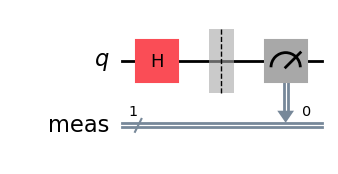

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1000, num_bits=1>)), metadata={'shots': 1000, 'circuit_metadata': {}})], metadata={'version': 2})
{'0': 535, '1': 465}


In [16]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.primitives import BackendSamplerV2
from IPython.display import display, Math

qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()
display(qc.draw("mpl"))


sampler = BackendSamplerV2(backend = Aer.get_backend("qasm_simulator"))

job = sampler.run([qc], shots=1000)

result = job.result()

print(result)

counts = result[0].data.meas.get_counts()

print(counts)

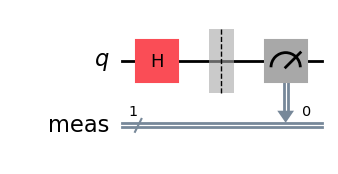

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1000, num_bits=1>)), metadata={'shots': 1000, 'circuit_metadata': {}})], metadata={'version': 2})
{'1': 511, '0': 489}


In [15]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from IPython.display import display, Math

qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()
display(qc.draw("mpl"))

sampler = StatevectorSampler()

result = sampler.run([qc], shots=1000).result()
print(result)

counts = result[0].data.meas.get_counts()

print(counts)


## Estimator Primitive

The **Estimator** primitive is used to calculate the **expectation value of an observable** for a quantum state prepared by a circuit.

It evaluates

$$
\boxed{\langle O\rangle=\langle\psi|O|\psi\rangle}
$$

where

- $|\psi\rangle$ is the state produced by the quantum circuit.

- $O$ is an observable.

- $\langle O\rangle$ is the expected measured value of that observable.

### Example

Suppose $$
|\psi\rangle
=\frac{1}{\sqrt2}
(|0\rangle+|1\rangle)
$$ and the observable is the Pauli-$Z$ operator $$
Z=\begin{bmatrix}
1&0\\
0&-1
\end{bmatrix}.
$$

- Then $$
\langle Z\rangle
=\langle\psi|Z|\psi\rangle = \frac12(1)+\frac12(-1) =
0.$$

- The Estimator is therefore useful when we want a **physical or mathematical quantity represented by an observable**, rather than individual measurement samples. 

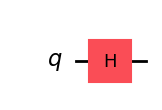

Expectation value: 0.0


In [17]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from IPython.display import display

# --------------------------------------------------
# Create quantum circuit
# --------------------------------------------------

qc = QuantumCircuit(1)
qc.h(0)
display(qc.draw("mpl"))

# --------------------------------------------------
# Define observable: Pauli-Z
# --------------------------------------------------
observable = SparsePauliOp("Z")
# --------------------------------------------------
# Create Estimator
# --------------------------------------------------
estimator = StatevectorEstimator()
# --------------------------------------------------
# Run Estimator
# --------------------------------------------------
result = estimator.run([
    (qc, observable)
]).result()
# --------------------------------------------------
# Get expectation value
# --------------------------------------------------
expectation_value = result[0].data.evs
print("Expectation value:", expectation_value)

## Sampler vs Estimator

| Primitive     | Main Purpose                            | Output                              |
| ------------- | --------------------------------------- | ----------------------------------- |
| **Sampler**   | Sample circuit outputs                  | Measurement samples / distributions |
| **Estimator** | Calculate observable expectation values | $\langle O\rangle$                  |


## Qiskit V2 Primitives

In modern Qiskit, the V2 primitive interfaces are based on

$$
\texttt{BaseSamplerV2}
$$

and

$$
\texttt{BaseEstimatorV2}.
$$

Qiskit's reference implementations are:

```python
from qiskit.primitives import StatevectorSampler
from qiskit.primitives import StatevectorEstimator
```

`StatevectorSampler` performs sampling using ideal statevector simulation, while `StatevectorEstimator` calculates expectation values using statevector simulation. 


# Qiskit Noise Parameters:

- In a real quantum computer, qubits and quantum gates are affected by imperfections. **Noise simulation** allows us to model these imperfections on a classical computer before running a circuit on real quantum hardware.

- In Qiskit Aer, a `NoiseModel` specifies which errors are applied to gates, resets, and measurements. Aer provides standard models such as depolarizing, thermal relaxation, amplitude damping, phase damping, Pauli errors, and readout errors.

## Depolarizing Error

A **depolarizing error** represents a generic loss of quantum-state fidelity. 

- It is controlled by an error parameter $p$. In Qiskit:

```python
from qiskit_aer.noise import depolarizing_error

error = depolarizing_error(p, 1)
```

- For an $n$-qubit system, the channel can be written as $$\mathcal{E}(\rho)=(1-p)\rho+p\frac{I}{2^n}$$ for the corresponding depolarizing parameterization. A larger error parameter generally means a stronger disturbance.

## Thermal Relaxation

- Real qubits interact with their environment. Their behavior is commonly characterized by two relaxation times:

    1. **$T_1$** $\implies T_1$ describes the characteristic **energy relaxation** time.
    
    2. **$T_2$** $\implies T_2$ describes the characteristic **decoherence/dephasing** time.

- The thermal-relaxation model also depends on the amount of time the qubit spends undergoing an operation.

- Qiskit Aer provides:

```python
from qiskit_aer.noise import thermal_relaxation_error

error = thermal_relaxation_error(T1, T2, gate_time)
```

- The physical constraint $$T_2\leq 2T_1$$ must be satisfied.

## Readout Error

- Even when the quantum operation is correct, the final measurement can be incorrect.

- For a single qubit, we can specify probabilities such as $$P(1|0)$$ meaning the probability of recording $1$ when the actual state was $0$, and $$
P(0|1) $$ meaning the probability of recording $0$ when the actual state was $1$.

- Qiskit represents this using `ReadoutError`.

# Noise Model

A `NoiseModel` combines one or more error sources and attaches them to particular circuit operations.

For example:

```python
from qiskit_aer.noise import NoiseModel

noise_model = NoiseModel()
```

We can then add errors to gates:

```python
noise_model.add_all_qubit_quantum_error(error, ["h"])
```

and to measurements:

```python
noise_model.add_all_qubit_readout_error(readout_error)
```

## Ideal vs Noisy Simulation

The difference can be understood as:

$$
\boxed{
\text{Ideal Circuit}
\rightarrow
\text{Perfect Quantum Operations}
}
$$

while

$$
\boxed{
\text{Noisy Circuit}
\rightarrow
\text{Quantum Operations + Errors}
}
$$

- The same circuit can therefore produce different measurement distributions.

# Important Noise Parameters

| Parameter | Represents                     | Effect                                  |                                 |
| --------- | ------------------------------ | --------------------------------------- | ------------------------------- |
| $p$       | Depolarizing error probability | Randomizes the quantum state            |                                 |
| $T_1$     | Energy relaxation time         | Loss of excited-state population        |                                 |
| $T_2$     | Coherence/dephasing time       | Loss of phase coherence                 |                                 |
| $t$       | Gate/operation duration        | Longer exposure can increase relaxation |                                 |
| $P(1      | 0)$                            | Readout error                           | $0$ incorrectly measured as $1$ |
| $P(0      | 1)$                            | Readout error                           | $1$ incorrectly measured as $0$ |

A device-derived Aer noise model can combine gate errors, thermal relaxation, and readout errors using hardware properties such as gate errors, gate durations, $T_1$, $T_2$, and readout-error parameters. 

## Example: Bell State

- Consider the circuit $$|00\rangle\xrightarrow{H\otimes I}\frac{1}{\sqrt2}(|00\rangle+|10\rangle)\xrightarrow{CNOT}\frac{1}{\sqrt2}(|00\rangle+|11\rangle)$$

- The ideal measurement results should be approximately $$P(00)=0.5 \text{ and}$$  $$P(11)=0.5.$$

- The outcomes $01$ and $10$ should ideally have probability $0$.

Circuit:


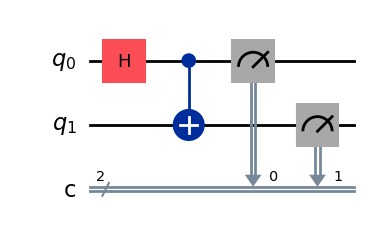

Ideal counts:
{'11': 973, '00': 1027}
Noisy counts:
{'01': 162, '11': 777, '00': 897, '10': 164}


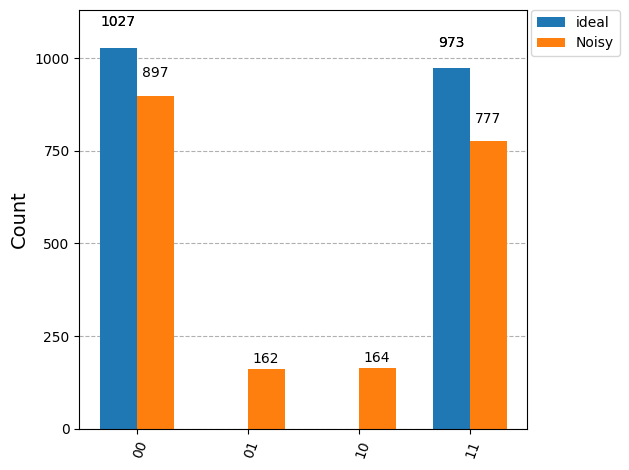

In [27]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    ReadoutError
)

# ==========================================================
# 1. Create Bell-state circuit
# ==========================================================

qc = QuantumCircuit(2, 2)

qc.h(0)
qc.cx(0, 1)

qc.measure([0, 1], [0, 1])

print("Circuit:")
display(qc.draw("mpl"))

# ==========================================================
# 2. Ideal Simulator
# ==========================================================

ideal_simulator = AerSimulator()

ideal_result = ideal_simulator.run(
    qc,
    shots=2000
).result()

ideal_counts = ideal_result.get_counts()

print("Ideal counts:")
print(ideal_counts)

# ==========================================================
# 3. Create Noise Model
# ==========================================================

noise_model = NoiseModel()

# Depolarizing error for single-qubit gates
single_qubit_error = depolarizing_error(
    0.02,     # error probability
    1
)

# Depolarizing error for two-qubit gates
two_qubit_error = depolarizing_error(
    0.05,     # error probability
    2
)

# Add errors to all qubits
noise_model.add_all_qubit_quantum_error(
    single_qubit_error,
    ["h"]
)

noise_model.add_all_qubit_quantum_error(
    two_qubit_error,
    ["cx"]
)

# ==========================================================
# 4. Add Readout Error
# ==========================================================

readout_error = ReadoutError([
    [0.95, 0.05],
    [0.10, 0.90]
])

noise_model.add_all_qubit_readout_error(
    readout_error
)

# ==========================================================
# 5. Noisy Simulator
# ==========================================================

noisy_simulator = AerSimulator(
    noise_model=noise_model
)

noisy_result = noisy_simulator.run(
    qc,
    shots=2000
).result()

noisy_counts = noisy_result.get_counts()

print("Noisy counts:")
print(noisy_counts)

# ==========================================================
# 6. Compare the Results
# ==========================================================

from qiskit.visualization import plot_histogram
legend = ['ideal', 'Noisy']
plot_histogram([ideal_counts,noisy_counts],legend=legend)

# Fake Backend Simulation

A **Fake Backend** is a local, simulated representation of an IBM Quantum device. It is useful when we want to test a quantum circuit against a **realistic hardware configuration without connecting to a real QPU**. The fake backend contains information such as the device's **number of qubits, coupling map, supported gates, and qubit/gate properties**.

## Why are Fake Backends useful?

They are mainly used for:

- **Testing and debugging** quantum circuits.

- Testing how **transpilation** behaves for a particular hardware architecture.

- Performing **noisy simulations** based on realistic device characteristics.

- Developing circuits locally before sending them to a real IBM Quantum backend. 


## Fake Backends in Modern Qiskit

For the Qiskit 2.4 ecosystem, IBM's fake backends are provided through the **`qiskit_ibm_runtime.fake_provider`** package.

- For example:

    ```python
    from qiskit_ibm_runtime.fake_provider import FakeManilaV2
    
    backend = FakeManilaV2()
    ```

- These V2 fake backends use **system snapshots** of IBM Quantum devices. The snapshots contain information such as:

$$
\text{Coupling Map}
$$

$$
\text{Basis Gates}
$$

$$
T_1,\quad T_2,\quad \text{Gate Errors}
$$ and other hardware properties. 



## Example

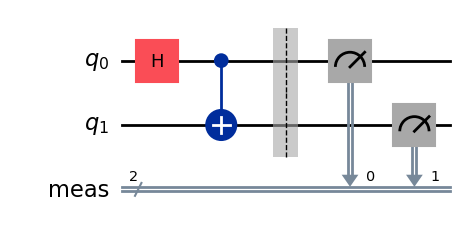

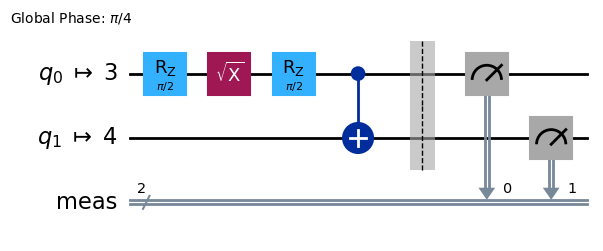

In [30]:
from qiskit import QuantumCircuit, transpile
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# Create fake backend
backend = FakeManilaV2()

# Create circuit
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

display(qc.draw("mpl"))

# Adapt circuit to the fake hardware
transpiled_qc = transpile(qc, backend)

display(transpiled_qc.draw("mpl"))

In [32]:
job = backend.run(transpiled_qc,shots=1000)
print(job.result())
print(job.result().get_counts())

Result(backend_name='aer_simulator', backend_version='0.17.2', job_id='3b805b27-da27-47ac-a9e3-0a3cda9560a9', success=True, results=[ExperimentResult(shots=1000, success=True, meas_level=2, data=ExperimentResultData(counts={'0x1': 14, '0x2': 14, '0x0': 486, '0x3': 486}), header={'creg_sizes': [['meas', 2]], 'global_phase': 0.7853981633974483, 'memory_slots': 2, 'n_qubits': 5, 'name': 'circuit-152', 'qreg_sizes': [['q', 5]], 'metadata': {}}, status=DONE, seed_simulator=325695436, metadata={'time_taken': 0.009538456, 'num_bind_params': 1, 'parallel_state_update': 24, 'parallel_shots': 1, 'required_memory_mb': 1, 'input_qubit_map': [[4, 1], [3, 0]], 'method': 'density_matrix', 'device': 'CPU', 'num_qubits': 2, 'sample_measure_time': 0.007860831, 'active_input_qubits': [3, 4], 'num_clbits': 2, 'remapped_qubits': True, 'runtime_parameter_bind': False, 'max_memory_mb': 63971, 'noise': 'superop', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusion': {'applied': False, 'max_

> Here, the transpiler uses the fake backend's hardware characteristics to determine how the circuit should be mapped to the device.

## Fake Backend vs AerSimulator

| Fake Backend                                        | AerSimulator                                     |
| --------------------------------------------------- | ------------------------------------------------ |
| Mimics a particular IBM QPU                         | General-purpose simulator                        |
| Contains hardware-specific information              | Does not inherently represent one particular QPU |
| Useful for hardware-aware transpilation             | Useful for general circuit simulation            |
| Can support noisy simulation using device snapshots | Can use explicitly defined noise models          |
| Example: `FakeManilaV2()`                           | Example: `AerSimulator()`                        |

$$
\boxed{\text{AerSimulator}=\text{Simulate a quantum computer}}
$$

$$
\boxed{\text{Fake Backend}=\text{Simulate a particular hardware target}}
$$